In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Start

In [ ]:
# Import/Save the model
import joblib

# Data cleaning and manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt

# Methods
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.utils.class_weight import compute_class_weight
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from scipy.stats import uniform, randint, loguniform
from sklearn.model_selection import StratifiedKFold

# Models
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC, LinearSVC
from sklearn.linear_model import LogisticRegression, PassiveAggressiveClassifier

# Transforming labels from string to categorical
from sklearn.preprocessing import LabelEncoder

# Metrics
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
from sklearn.metrics import (roc_auc_score, roc_curve, auc,
    confusion_matrix, precision_recall_curve, average_precision_score)

%matplotlib inline

In [ ]:
# Abstract:
# 1. Baseline
# 2. Cleaned
# 3. NER

# Datasets:
# Enron - Done
# SpamAssassin - Done
# LingSpam -

abstract = "NER"
dataset = "LingSpam"

## Data Loading and Ecoding the Target Variable

In [ ]:
df = pd.read_csv(f'drive/MyDrive/Dissertation/Datasets/{abstract}/{dataset}/{dataset}_{abstract}.csv')
df.shape, df.columns

((2893, 4),
 Index(['text', 'label', 'expanded_text', 'processed_text'], dtype='object'))

In [ ]:
# Fix the print
before = len(df)
df = df.drop_duplicates(subset=['text']).reset_index(drop=True)
after = len(df)
print(f"Before dedup: {before}")
print(f"After dedup: {after}")
print(f"Removed: {before - after} rows")

Before dedup: 2893
After dedup: 2859
Removed: 34 rows


In [ ]:
df.head()

,text,label,expanded_text,processed_text
0,content - length : 3386 apple-iss research cen...,0,content-length : 3386 apple-iss research cente...,content - length : NUMNER apple - iss research...
1,"lang classification grimes , joseph e . and ba...",0,"lang classification grimes , joseph e . and ba...","ORGNER , PERNER and PERNER PERNER ; ethnologue..."
2,i am posting this inquiry for sergei atamas ( ...,0,i am posting this inquiry for sergei atamas ( ...,i am posting this inquiry for PERNER ( EMAILNE...
3,a colleague and i are researching the differin...,0,a colleague and i are researching the differin...,a colleague and i are researching the differin...
4,earlier this morning i was on the phone with a...,0,earlier this morning i was on the phone with a...,TIMENER i was on the phone with a friend of mi...


## Dataset Splitting and TF-IDF Feature Transformation

In [ ]:
# First split
X_train80, X_test, y_train80, y_test = train_test_split(
    df['text'], # processed_text
    df['label'],
    test_size=0.2,
    stratify=df['label'],
    random_state=42
)

# Validation split
val_percent = 0.10 / (1 - 0.2)

X_train70, X_val, y_train70, y_val = train_test_split(
    X_train80,
    y_train80,
    test_size=val_percent,
    stratify=y_train80,
    random_state=42
)

In [ ]:
# TF-IDF vectorization
vectorizer = TfidfVectorizer(
    min_df=3, max_df=0.95,
    max_features=5_000,
    lowercase=True,
    ngram_range=(1, 4))

In [ ]:
joblib.dump(vectorizer, f'drive/MyDrive/Dissertation/Results/{abstract}/{dataset}/Features/Tfidf_{dataset}.pkl')

['drive/MyDrive/Dissertation/Results/NER/LingSpam/Features/Tfidf_LingSpam.pkl']

In [ ]:
# Vectorize the X_train and X_test
# X_train_tfidf is used for training
X_train_tfidf = vectorizer.fit_transform(X_train70).toarray()
# X_test_tfidf is used for testing
X_test_tfidf = vectorizer.transform(X_test).toarray()
# X_val_tfidf is used for valiation
X_val_tfidf = vectorizer.transform(X_val).toarray()

In [ ]:
# (572219990, (3358, 170405))
X_train_tfidf.size, X_train_tfidf.shape

(10005000, (2001, 5000))

In [ ]:
X_test_tfidf.size, X_test_tfidf.shape

(2860000, (572, 5000))

In [ ]:
X_val_tfidf.size, X_val_tfidf.shape

(1430000, (286, 5000))

## Robust Model Selection and Hyperparameter Optimization Pipeline

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pipelines = {
  'Multinomial Naive Bayes': Pipeline([('classifier', MultinomialNB())]),
  'Logistic Regression' : Pipeline([('classifier', LogisticRegression(random_state=42))]),
  'Linear SVM' : Pipeline([('classifier', LinearSVC(random_state=42))]),
}

In [ ]:
# Define parameter grids specific to each model
param_RandomSearch = {
    'Multinomial Naive Bayes': {
        'classifier__alpha': loguniform(1e-3, 2.0)
    },

    'Logistic Regression': {
        'classifier__C': loguniform(1e-3, 10), # Uniformly distributed C (log scale)
        'classifier__solver': ['liblinear'], # Fast solver
    },
    'Linear SVM': {
        # Low C value means low margins that said more values between bounaries
        # Likewize, higgher C value means higher margins that said les values between bounaries
        'classifier__C': loguniform(1e-3, 10),
    },
}

In [ ]:
# Computing the class weight (Imbalance dataset)
def imbalance_dataset(y_train_data):
  # Calculate class weights once for the entire training set
  classes = np.unique(y_train_data)
  weights = compute_class_weight('balanced', classes=classes, y=y_train_data)
  class_weights_dict = {c: w for c, w in zip(classes, weights)}

  # Create the sample_weight array
  sample_weights = np.array([class_weights_dict[label] for label in y_train_data])

  return sample_weights, class_weights_dict

weight_results, class_weight = imbalance_dataset(y_train70)

In [ ]:
weight_results, class_weight

(array([0.59518144, 0.59518144, 3.1265625 , ..., 3.1265625 , 0.59518144,
        0.59518144]),
 {np.int64(0): np.float64(0.5951814396192743),
  np.int64(1): np.float64(3.1265625)})

In [ ]:
results: list = []
names: list   = ['Ham', 'Spam']

XTrainTfidf = X_train_tfidf.copy()
XTestTfidf = X_test_tfidf.copy()
yTrain = y_train70.copy()
yTest  = y_test.copy()

# Combine pipelines and parameter grids into RandomSearchCV
for model, pipe in pipelines.items():
    model_name : str = "".join(model.split(" "))

    # Model Hyperparameters
    param_grid = param_RandomSearch[model]

    random_search = RandomizedSearchCV(
      estimator=pipe,
      param_distributions=param_grid,
      cv=cv,
      n_iter=50,
      n_jobs=-1,
      scoring='average_precision',   # PR-AUC
      refit=True, #'average_precision',
      return_train_score=True,
      verbose=3,
    )

    random_search.fit(XTrainTfidf, yTrain, classifier__sample_weight=weight_results)

    # Get the best model
    best_model = random_search.best_estimator_
    parameters = random_search.best_params_

    final_classifier = best_model.named_steps['classifier']

    if hasattr(final_classifier, 'predict_proba'):
      y_score_val = best_model.predict_proba(X_val_tfidf)[:, 1]
    else:
      y_score_val = best_model.decision_function(X_val_tfidf)

    # Calculating the Threshold
    precision, recall, thresholds = precision_recall_curve(y_val, y_score_val)

    f1_scores_all = 2 * recall[:-1] * precision[:-1] / (recall[:-1] + precision[:-1] + 1e-10)

    best_idx = np.argmax(f1_scores_all)
    best_threshold = thresholds[best_idx]

    print(f"Predictions generated using {best_threshold:.4f} threshold.")

    # Predict on the test set
    if hasattr(final_classifier, 'predict_proba'):
      y_score = best_model.predict_proba(XTestTfidf)[:, 1]
    else:
      y_score = best_model.decision_function(XTestTfidf)

    y_pred = (y_score >= best_threshold).astype(int)

    # Calculate metrics
    test_accuracy = accuracy_score(yTest, y_pred)
    test_precision = precision_score(yTest, y_pred)
    test_recall = recall_score(yTest, y_pred)
    test_f1_score = f1_score(yTest, y_pred)

    # Confusion Matrix for TP, TN, FP, FN
    cm = confusion_matrix(yTest, y_pred)
    tn, fp, fn, tp = cm.ravel()  # Extracting true negative, false positive, false negative, true positive

    # Display confusion matrix
    fig, ax = plt.subplots(figsize=(8,6))
    ConfusionMatrixDisplay.from_predictions(yTest, y_pred, cmap='Blues', ax=ax)
    ax.set_title(f" {model_name} Confusion Matrix")
    plt.savefig(fname=f'drive/MyDrive/Dissertation/Results/{abstract}/{dataset}/Image/Machin Learning/{model_name}_confusionMatrix.png', format='png') # ../images/machineLearning/
    plt.close()

    # Display Threshold vs F1-Score
    fig, ax = plt.subplots(figsize=(8,6))
    ax.plot(thresholds, f1_scores_all)
    ax.set_xlabel('Threshold')
    ax.set_ylabel('F1 Score')
    ax.set_title(f'{model_name} F1 Score vs Threshold (Validation)')
    ax.axvline(best_threshold, color='red', linestyle='--')
    plt.savefig(fname=f'drive/MyDrive/Dissertation/Results/{abstract}/{dataset}/Image/Machin Learning/{model_name}_Threshold_F1.png', format='png')
    plt.close()

    fpr, tpr, _ = roc_curve(yTest, y_score)
    roc_auc = auc(fpr, tpr)

    # Display ROC Curve
    fig, ax = plt.subplots(figsize=(8,6))
    ax.plot(fpr, tpr, lw=2, label=f'ROC (AUC = {roc_auc:.3f})')
    ax.plot([0, 1], [0, 1], linestyle='--')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title(f'{model_name} ROC Curve')
    ax.legend(loc='lower right')
    ax.grid(True)
    plt.savefig(fname=f'drive/MyDrive/Dissertation/Results/{abstract}/{dataset}/Image/Machin Learning/{model_name}_roc_curve.png', format='png')
    plt.close()

    test_precision_curve, test_recall_curve, _ = precision_recall_curve(yTest, y_score)
    pr_auc = average_precision_score(yTest, y_score)

    # Plotting PR Curve
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.plot(test_recall_curve, test_precision_curve, lw=2, label=f'PR (AP = {pr_auc:.3f})')
    ax.set_xlabel('Recall')
    ax.set_ylabel('Precision')
    ax.set_title(f'{model_name} Precision-Recall Curve')
    ax.legend(loc='lower left')
    ax.grid(True)
    plt.savefig(fname=f'drive/MyDrive/Dissertation/Results/{abstract}/{dataset}/Image/Machin Learning/{model_name}_pr_curve.png')
    plt.close()

    # Store results in a dictionary
    results.append({
        'Model': model,
        'Parameter': parameters,
        'Accuracy': np.round(test_accuracy, 3),
        'Precision': np.round(test_precision, 3),
        'Recall': np.round(test_recall, 3),
        'F1-Score': np.round(test_f1_score, 3),
        'PR-AUC': np.round(pr_auc, 3),
        'ROC-AUC': np.round(roc_auc, 3),
        'Threshold' : np.round(best_threshold, 3),
        'TP': tp,
        'TN': tn,
        'FP': fp,
        'FN': fn
    })

    # Display the Test parameters and model
    print("Test Classifier:", best_model)
    print("Test Parameters:", parameters)
    print("Test CV:", cv)
    print("Test Accuracy:", test_accuracy)
    print("Test Precision:", test_precision)
    print("Test Recall:", test_recall)
    print("Test F1-Score:", test_f1_score)
    print("Test Threshold:", best_threshold)

    report = classification_report(yTest, y_pred, target_names=names, output_dict=True)
    model_dataframe = pd.DataFrame(report).transpose()

    # Save the classification report to a CSV file
    model_dataframe.to_csv(f'drive/MyDrive/Dissertation/Results/{abstract}/{dataset}/Results/report_{model_name}.csv', index=True)# ../data/machineLearning/

    # Saving the model
    joblib.dump(best_model, f"drive/MyDrive/Dissertation/Results/{abstract}/{dataset}/Predicted/{model_name}.pkl") # ../models/machineLearning/
    # print()

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Predictions generated using 0.9077 threshold.
Test Classifier: Pipeline(steps=[('classifier',
                 MultinomialNB(alpha=np.float64(0.12457319959394862)))])
Test Parameters: {'classifier__alpha': np.float64(0.12457319959394862)}
Test CV: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)
Test Accuracy: 0.9895104895104895
Test Precision: 0.9574468085106383
Test Recall: 0.9782608695652174
Test F1-Score: 0.967741935483871
Test Threshold: 0.9077314872349441
Fitting 5 folds for each of 50 candidates, totalling 250 fits
Predictions generated using 0.5478 threshold.
Test Classifier: Pipeline(steps=[('classifier',
                 LogisticRegression(C=np.float64(9.346724149053282),
                                    random_state=42, solver='liblinear'))])
Test Parameters: {'classifier__C': np.float64(9.346724149053282), 'classifier__solver': 'liblinear'}
Test CV: StratifiedKFold(n_splits=5, random_state=42, shuffl

In [ ]:
results_df_demo = pd.DataFrame(results)

In [ ]:
results_df_demo

,Model,Parameter,Accuracy,Precision,Recall,F1-Score,PR-AUC,ROC-AUC,Threshold,TP,TN,FP,FN
0,Multinomial Naive Bayes,{'classifier__alpha': 0.12457319959394862},0.990,0.957,0.978,0.968,0.998,1.0,0.908,90,476,4,2
1,Logistic Regression,"{'classifier__C': 9.346724149053282, 'classifi...",0.993,0.958,1.000,0.979,0.999,1.0,0.548,92,476,4,0
2,Linear SVM,{'classifier__C': 5.900874476816148},0.993,0.978,0.978,0.978,0.998,1.0,0.118,90,478,2,2


In [ ]:
results_df_demo.sort_values(by='Accuracy', ascending=False)

,Model,Parameter,Accuracy,Precision,Recall,F1-Score,PR-AUC,ROC-AUC,Threshold,TP,TN,FP,FN
1,Logistic Regression,"{'classifier__C': 9.346724149053282, 'classifi...",0.993,0.958,1.000,0.979,0.999,1.0,0.548,92,476,4,0
2,Linear SVM,{'classifier__C': 5.900874476816148},0.993,0.978,0.978,0.978,0.998,1.0,0.118,90,478,2,2
0,Multinomial Naive Bayes,{'classifier__alpha': 0.12457319959394862},0.990,0.957,0.978,0.968,0.998,1.0,0.908,90,476,4,2


In [ ]:
results_df_demo.to_csv(f"drive/MyDrive/Dissertation/Results/{abstract}/{dataset}/Results/report_ML.csv", index=False)

# Diagrams Extra
1. ROC and AUC charts -- Done
2. Confusion matrix for each model -- Done  

In [ ]:
svm = joblib.load('SupportVectorMachine.pkl')

In [ ]:
import joblib
from sklearn.metrics import precision_recall_curve, auc

ml_models : list = ["LogisticRegression.pkl", "MultinomialNaiveBayes.pkl", "SupportVectorMachine.pkl"]

for i, model in enumerate(ml_models):
  print(f"{i + 1}. {model}")
  # Load your saved model
  best_model = joblib.load(f"{model}")

  if i < 2:
    # Predict probabilities for the positive class (Spam)
    y_scores = best_model.predict_proba(XTestTfidf)[:, 1]
  else:
    y_scores = best_model.decision_function(XTestTfidf)

  # Compute precision-recall curve
  precision, recall, thresholds = precision_recall_curve(y_test, y_scores)

  # Compute area under the PR curve
  pr_auc = auc(recall, precision)

  print(f"PR-AUC: {pr_auc:.4f}")
  print('\n','-'*40,'\n')


1. LogisticRegression.pkl
PR-AUC: 0.9994

 ---------------------------------------- 

2. MultinomialNaiveBayes.pkl
PR-AUC: 0.9694

 ---------------------------------------- 

3. SupportVectorMachine.pkl
PR-AUC: 0.9996

 ---------------------------------------- 



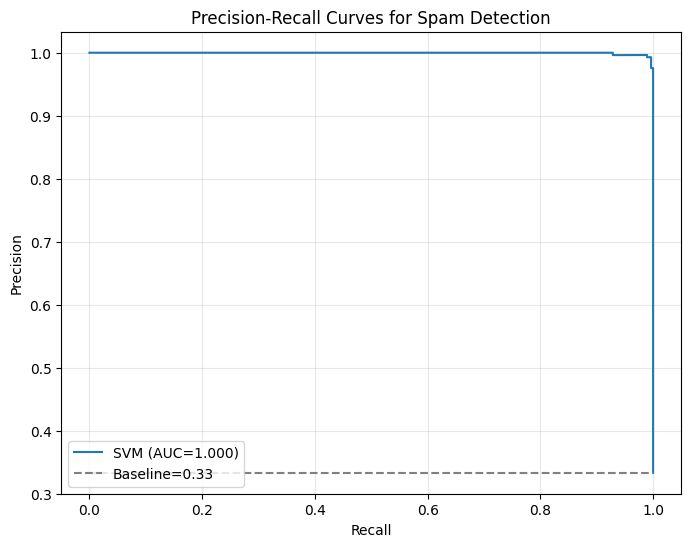

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, auc
import joblib

# Load your models
models = {
    # "Logistic Regression": joblib.load("LogisticRegression.pkl"),
    # "Multinomial NB": joblib.load("MultinomialNaiveBayes.pkl"),
    "SVM": joblib.load("SupportVectorMachine.pkl")
}

plt.figure(figsize=(8,6))

# Loop through models and plot PR curve
for name, model in models.items():
    # PAC needs decision_function, others use predict_proba
    if hasattr(model, "predict_proba"):
        y_scores = model.predict_proba(XTestTfidf)[:, 1]
    else:
        y_scores = model.decision_function(XTestTfidf)

    precision, recall, _ = precision_recall_curve(y_test, y_scores)
    pr_auc = auc(recall, precision)

    plt.plot(recall, precision, label=f"dataset (AUC={pr_auc:.3f})")

# Baseline (random guess = ratio of positives)
baseline = sum(y_test) / len(y_test)
plt.hlines(baseline, 0, 1, colors="gray", linestyles="--", label=f"Baseline={baseline:.2f}")

# Styling
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves for Spam Detection")
plt.legend(loc="lower left")
plt.grid(alpha=0.3)
# plt.show()
plt.savefig(fname=f'PR_AUC_spam_SpaCyActivated.png', format='png')

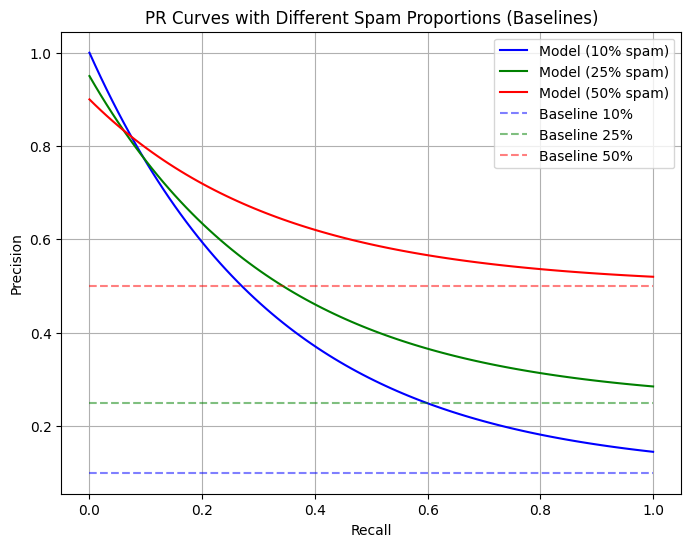

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Recall range (0 to 1)
recall = np.linspace(0, 1, 100)

# Simulated precision curves (toy example)
precision_10 = 0.1 + 0.9 * np.exp(-3 * recall)  # performs above 10% baseline
precision_25 = 0.25 + 0.7 * np.exp(-3 * recall) # performs above 25% baseline
precision_50 = 0.5 + 0.4 * np.exp(-3 * recall)  # performs above 50% baseline

# Baselines
baseline_10 = [0.10] * len(recall)
baseline_25 = [0.25] * len(recall)
baseline_50 = [0.50] * len(recall)

plt.figure(figsize=(8,6))

# Plot curves
plt.plot(recall, precision_10, label="Model (10% spam)", color="blue")
plt.plot(recall, precision_25, label="Model (25% spam)", color="green")
plt.plot(recall, precision_50, label="Model (50% spam)", color="red")

# Plot baselines
plt.plot(recall, baseline_10, linestyle="--", color="blue", alpha=0.5, label="Baseline 10%")
plt.plot(recall, baseline_25, linestyle="--", color="green", alpha=0.5, label="Baseline 25%")
plt.plot(recall, baseline_50, linestyle="--", color="red", alpha=0.5, label="Baseline 50%")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("PR Curves with Different Spam Proportions (Baselines)")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
import joblib

# 1. Load your trained pipeline (TF-IDF + model)
model = joblib.load("SupportVectorMachine.pkl")  # change name if needed

# 2. Some example messages
messages = [
    "Congratulations! You have won a $1000 Walmart gift card. Click here to claim your prize now!",  # Spam
    "Hey, are we still on for lunch tomorrow at 12?",  # Ham
    "URGENT! Your account has been suspended. Verify your information immediately.",  # Spam
    "Don’t forget to bring the book for class today.",  # Ham
    "You’ve been selected for a free vacation trip to Bahamas! Call now!",  # Spam
    "Hi mom, just wanted to check if you’re doing okay."  # Ham
]

# 3. Make predictions
X_test_example = vectorizer.transform(messages)
# proba = model.predict_proba(X_test_example)[:,1]  # probability of Spam
proba = model.decision_function(X_test_example)


for msg, score in zip(messages, proba):
    print(f"Message: {msg}")
    print(f"Spam probability: {score:.3f}")
    print(f"Prediction @0.5: {'Spam' if score >= 0.5 else 'Ham'}")
    print(f"Prediction @0.3: {'Spam' if score >= 0.3 else 'Ham'}")  # test lower threshold
    print("-"*50)

print("Bahamas" in vectorizer.vocabulary_)
print("vacation" in vectorizer.vocabulary_)
print("gift" in vectorizer.vocabulary_)

ValueError: cannot use sparse input in 'SVC' trained on dense data